# ¿Qué ediciones de Wikipedia hay que revisar primero?
## Aprendizaje automático sobre el flujo de ediciones anónimas y detección de *model drift*

**Aprendizaje Automático en Series Temporales y Flujos de Datos · Máster en IA Aplicada (UC3M) · Curso 2026/27**

Grupo: _(nombres)_

> **Estado de este notebook:** primera parte del proyecto, hasta la **detección de data drift y concept drift**. La adaptación del modelo ante el drift y la comparación final de estrategias se añadirán en la siguiente fase.

## 1. Introducción

Cualquiera puede editar Wikipedia. La gran mayoría de las ediciones son correctas, pero una parte son vandalismo, pruebas o errores que los voluntarios acaban **deshaciendo** (*revert*). En la Wikipedia en inglés llegan cientos de ediciones anónimas por hora, así que nadie puede revisarlas todas: hace falta **priorizar**.

Las ediciones llegan una a una, de forma continua y sin fin: es un caso natural de **flujo de datos**. Además, el comportamiento de quien edita y de quien revisa cambia con el tiempo (hora del día, días de la semana, noticias que atraen vandalismo a ciertas páginas, cambios en las herramientas de Wikipedia…). Un modelo entrenado una vez y congelado puede dejar de ser válido: es el problema del **model drift**, que en la asignatura descomponemos en:

- **Data drift**: cambia la distribución de las variables de entrada, $P(X)$.
- **Concept drift**: cambia la relación entre las variables y la etiqueta, $P(y \mid X)$.

## 2. Objetivo

Construir un sistema que, para cada edición anónima que llega, estime el **riesgo de que acabe revertida**, aprendiendo de forma incremental con **River**, y **vigilar si ese modelo deja de ser válido con el tiempo**.

En esta primera parte nos centramos en:

1. Describir el flujo de datos y su evolución temporal.
2. Definir la estrategia de aprendizaje online y la evaluación *prequential* con modelos de referencia (*baseline*).
3. **Detectar data drift** con tres técnicas (KSWIN, ADWIN y Page-Hinkley) y **concept drift** con tres técnicas (DDM, EDDM y HDDM_W), justificando por qué las elegimos y analizando por qué unas funcionan mejor que otras en este flujo.

## 3. Trabajos similares (estado del arte breve)

**Detección de vandalismo en Wikipedia.**
- *ClueBot NG* (desde 2010) es el bot que revierte vandalismo automáticamente en la Wikipedia en inglés; usa una red neuronal sobre características de la edición y del texto, con un umbral muy conservador para evitar falsos positivos.
- Potthast et al. (2008, 2010) plantearon el problema como clasificación supervisada y crearon el corpus PAN-WVC; Adler et al. (2011) combinaron variables de metadatos, texto y reputación del autor, y mostraron que **los metadatos** (tamaño del cambio, comentario, tipo de usuario, hora) ya aportan mucho.
- Wikimedia publica hoy su propio modelo de **riesgo de reversión** (*Revert Risk*, sucesor de ORES), que puntúa cada edición en tiempo real. Nuestro planteamiento es el mismo problema, pero resuelto **en flujo** y vigilando explícitamente su degradación.

**Aprendizaje en flujo y drift.**
- Gama et al. (2014), *A survey on concept drift adaptation*, es la referencia general sobre tipos de drift y estrategias.
- Detectores que usamos: DDM (Gama et al., 2004), EDDM (Baena-García et al., 2006), HDDM (Frías-Blanco et al., 2015), ADWIN (Bifet y Gavaldà, 2007), KSWIN (Raab et al., 2020) y Page-Hinkley (Page, 1954).
- La evaluación *prequential* (*test-then-train*) sigue a Dawid (1984) y Gama et al. (2013); en River se implementa con `evaluate.progressive_val_score` o con un bucle manual equivalente.

## 4. Desarrollo

### 4.1 Configuración

In [1]:
# En Colab: instala River si no está disponible
try:
    import river
except ImportError:
    %pip install -q river
    import river

import os, math, time, urllib.request
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from river import compose, drift, dummy, feature_extraction, linear_model, metrics, preprocessing, stream, tree

print("River", river.__version__)

# Los nombres de HDDM cambiaron entre versiones de River (HDDM_W -> HDDMW)
HDDM_W = getattr(drift.binary, "HDDM_W", None) or getattr(drift.binary, "HDDMW")
# stream.iter_pandas pasa a llamarse stream.iter_frame en las versiones recientes
iter_frame = getattr(stream, "iter_frame", None) or stream.iter_pandas

SEMILLA = 42
np.random.seed(SEMILLA)
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3})

River 0.26.1


### 4.2 El flujo de datos

**Origen.** Las ediciones proceden de la API pública de Wikipedia (`list=recentchanges`), que para cada edición devuelve sus metadatos y sus **etiquetas** (*tags*). Wikipedia marca con la etiqueta `mw-reverted` las ediciones que después alguien deshace: esa es nuestra **variable objetivo** (`revertida`).

**Por qué lo tratamos como un flujo simulado y no en directo.** El flujo en directo (Wikimedia EventStreams) emite cada edición en el momento en que ocurre, pero **la etiqueta llega horas después** (cuando alguien la revierte). Para poder evaluar y detectar concept drift necesitamos las etiquetas, así que:

1. Descargamos **10 días completos** de ediciones (del 8 al 17 de octubre de 2026, UTC) con el script `descargar_datos.py`. Al descargarlas días después, las etiquetas ya están "maduras".
2. Guardamos el resultado en un CSV y lo **reproducimos en orden cronológico, edición a edición**, con `river.stream.iter_pandas`. El modelo ve cada edición una sola vez y en el mismo orden en que ocurrió, como en producción.

Esto es exactamente lo que en las diapositivas (S2) se llama *simular un flujo de datos a partir de un CSV*. Además el CSV hace el trabajo **reproducible**: la API solo guarda unos 30 días de historial.

**Filtros.** Solo Wikipedia en inglés, solo artículos (espacio de nombres 0), solo ediciones **anónimas** (IP o cuentas temporales `~2026-…`) y sin bots. Las ediciones anónimas son las que más se revierten (≈25 %), lo que da suficientes positivos para aprender; a cambio, el modelo no puede usar "es anónimo" como pista.

In [2]:
RUTA_CSV = "data/ediciones_wikipedia.csv.gz"
URL_CSV = "https://raw.githubusercontent.com/javiacey16/proyecto-series-temporales/main/data/ediciones_wikipedia.csv.gz"

if not os.path.exists(RUTA_CSV):          # p. ej. en Colab: lo bajamos del repositorio
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve(URL_CSV, RUTA_CSV)

df = pd.read_csv(RUTA_CSV, parse_dates=["timestamp"])
df["timestamp"] = df["timestamp"].dt.tz_localize(None)          # todas las horas están en UTC
df = df.sort_values(["timestamp", "revid"]).reset_index(drop=True)
print(f"{len(df):,} ediciones | desde {df.timestamp.min()} hasta {df.timestamp.max()}")
df.head()

122,679 ediciones | desde 2026-10-08 00:00:12 hasta 2026-10-17 23:59:57


,revid,timestamp,title,comment,user_es_ip,minor,new,oldlen,newlen,revertida
0,1379100748,2026-10-08 00:00:12,Reggie McFadden,NaN,False,False,False,8720,8731,False
1,1379100761,2026-10-08 00:00:16,Laurie Berkner,NaN,False,False,False,15961,15847,False
2,1379100768,2026-10-08 00:00:19,Nasim Nuñez,/* */,False,False,False,8753,8754,False
3,1379100781,2026-10-08 00:00:23,Skydance Corporation,They are normally stylized in their logo in al...,False,False,False,26599,26652,False
4,1379100786,2026-10-08 00:00:26,List of films shot in Baku,/* Films and television series */,False,False,False,1685,1714,False


**Variables.** Solo usamos información que **también está disponible en el instante en que llega la edición** (si usáramos algo posterior, como otras etiquetas, habría fuga de información):

| Variable | Tipo | Idea |
|---|---|---|
| `cambio_tam` | numérica | Bytes añadidos o quitados (con signo, escala log). Borrar mucho texto es sospechoso |
| `tam_final` | numérica | Tamaño de la página tras la edición (log) |
| `long_resumen` | numérica | Longitud del resumen que escribe quien edita (log) |
| `resumen_vacio`, `edicion_seccion` | binarias | Sin resumen / resumen automático de sección `/* … */` |
| `quita_texto` | binaria | La edición reduce el tamaño de la página |
| `hora_sin`, `hora_cos` | numéricas | Hora del día (UTC) codificada de forma cíclica |
| `resumen` | texto | Palabras del resumen (bolsa de palabras incremental de River) |

**Variables descartadas.** La API también indica si la edición es *menor*, si crea una página *nueva* y si el autor es una IP o una cuenta temporal. En nuestro flujo las tres son **constantes**: los usuarios anónimos no pueden marcar ediciones como menores ni crear artículos, y desde 2025 la Wikipedia en inglés asigna **cuentas temporales** (`~2026-…`) en lugar de mostrar la IP. Una variable constante no aporta nada, así que no las usamos (la comprobación está en la celda siguiente).

In [3]:
NUMERICAS = ["cambio_tam", "tam_final", "long_resumen", "resumen_vacio", "edicion_seccion",
             "quita_texto", "hora_sin", "hora_cos"]

def construir_variables(df):
    cambio = (df["newlen"] - df["oldlen"]).astype(float)
    hora = df["timestamp"].dt.hour + df["timestamp"].dt.minute / 60
    resumen = df["comment"].fillna("").astype(str)
    X = pd.DataFrame({
        "cambio_tam": np.sign(cambio) * np.log1p(np.abs(cambio)),
        "tam_final": np.log1p(df["newlen"].clip(lower=0)),
        "long_resumen": np.log1p(resumen.str.len()),
        "resumen_vacio": (resumen.str.strip() == "").astype(int),
        "edicion_seccion": resumen.str.startswith("/*").astype(int),
        "quita_texto": (cambio < 0).astype(int),
        "hora_sin": np.sin(2 * np.pi * hora / 24),
        "hora_cos": np.cos(2 * np.pi * hora / 24),
        # el texto se limpia del bloque /* sección */ para quedarnos con lo que escribe la persona
        "resumen": resumen.str.replace(r"/\*.*?\*/", " ", regex=True).str.strip(),
    })
    y = df["revertida"].astype(bool)
    return X, y

print("Proporción de ediciones menores, nuevas y de IP:",
      df[["minor", "new", "user_es_ip"]].mean().round(4).to_dict())

X, y = construir_variables(df)
print(f"Tasa global de reversión: {y.mean():.1%}  ({y.sum():,} de {len(y):,})")
X.describe().T.round(2)

Proporción de ediciones menores, nuevas y de IP: {'minor': 0.0, 'new': 0.0, 'user_es_ip': 0.0}


Tasa global de reversión: 25.0%  (30,722 de 122,679)


,count,mean,std,min,25%,50%,75%,max
cambio_tam,122679.0,1.38,3.53,-12.18,-1.10,2.08,4.03,12.88
tam_final,122679.0,9.99,1.17,2.30,9.20,10.02,10.83,13.43
long_resumen,122679.0,2.43,1.53,0.00,1.79,2.77,3.43,6.22
resumen_vacio,122679.0,0.22,0.42,0.00,0.00,0.00,0.00,1.00
edicion_seccion,122679.0,0.57,0.49,0.00,0.00,1.00,1.00,1.00
quita_texto,122679.0,0.28,0.45,0.00,0.00,0.00,1.00,1.00
hora_sin,122679.0,-0.12,0.70,-1.00,-0.80,-0.24,0.58,1.00
hora_cos,122679.0,-0.02,0.70,-1.00,-0.72,-0.03,0.68,1.00


**Posibles problemas del procesamiento continuo** (los tenemos en cuenta en el diseño):

- **Etiqueta retardada.** En producción la etiqueta llega horas después. Aquí la damos justo tras predecir (validación progresiva sin retardo, `delay=0`); es una simplificación que discutimos al final.
- **Desbalanceo moderado** (≈1 de cada 4 se revierte): la *accuracy* sola engaña, por eso usamos también ROC AUC.
- **Ráfagas**: un mismo vándalo o una "guerra de ediciones" producen muchas ediciones seguidas muy parecidas.
- **Estacionalidad diaria**: el volumen y el tipo de ediciones cambian según la hora (qué parte del mundo está despierta). Es un cambio *recurrente*, no un cambio permanente de concepto, y veremos que confunde a algunos detectores.

### 4.3 Comportamiento y evolución del flujo

Antes de modelar, miramos cómo evoluciona el flujo hora a hora: volumen, tasa de reversión y las variables numéricas principales.

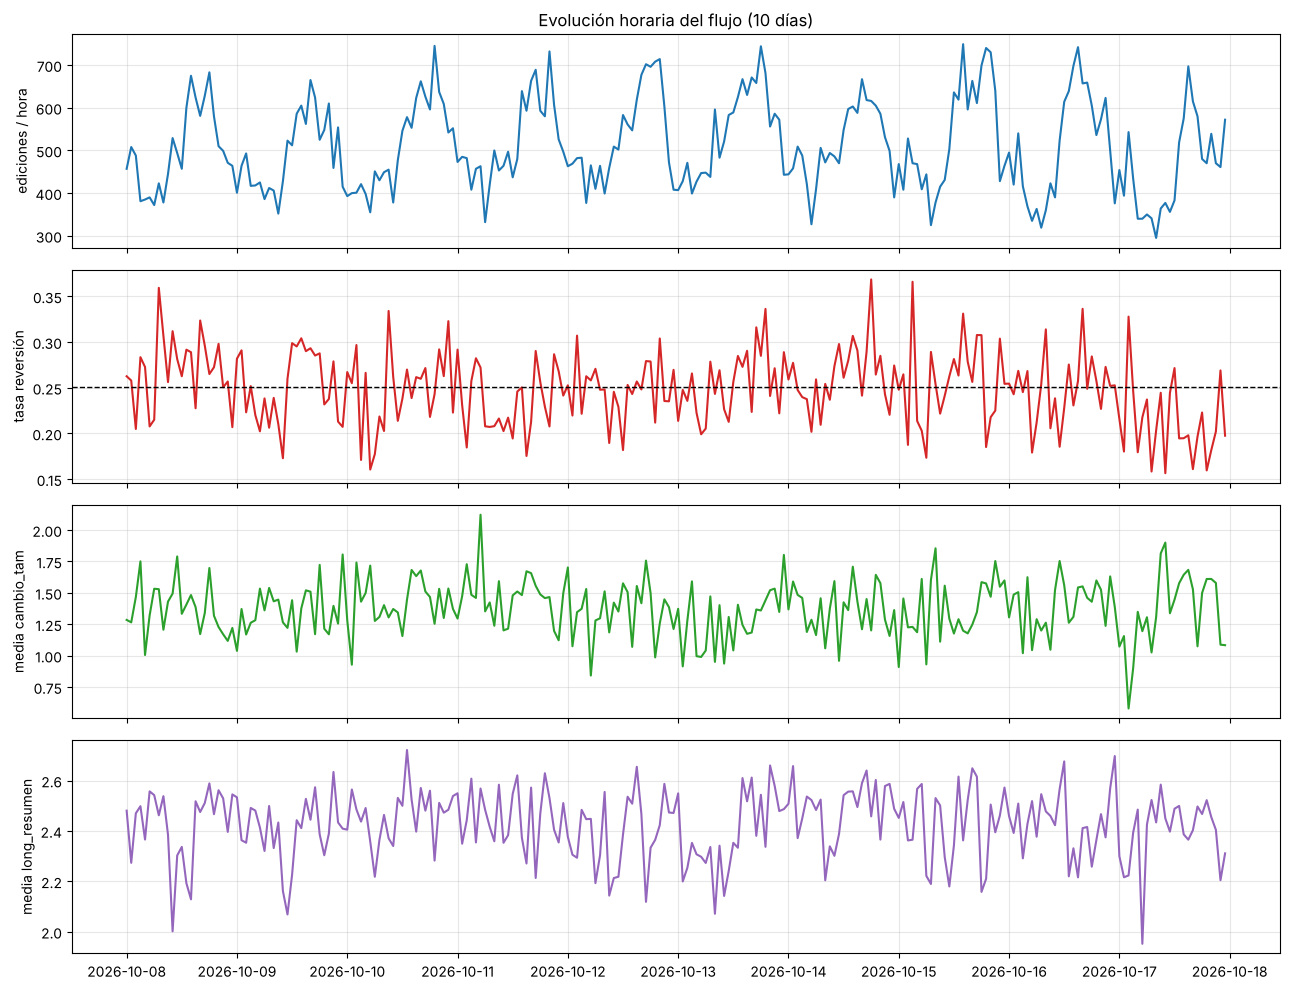

In [4]:
por_hora = pd.DataFrame({"ediciones": y.groupby(df["timestamp"].dt.floor("h")).size(),
                         "tasa_rev": y.groupby(df["timestamp"].dt.floor("h")).mean(),
                         "cambio_tam": X["cambio_tam"].groupby(df["timestamp"].dt.floor("h")).mean(),
                         "long_resumen": X["long_resumen"].groupby(df["timestamp"].dt.floor("h")).mean()})

fig, ax = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
ax[0].plot(por_hora.index, por_hora["ediciones"]); ax[0].set_ylabel("ediciones / hora")
ax[1].plot(por_hora.index, por_hora["tasa_rev"], color="tab:red"); ax[1].set_ylabel("tasa reversión")
ax[1].axhline(y.mean(), color="k", ls="--", lw=1)
ax[2].plot(por_hora.index, por_hora["cambio_tam"], color="tab:green"); ax[2].set_ylabel("media cambio_tam")
ax[3].plot(por_hora.index, por_hora["long_resumen"], color="tab:purple"); ax[3].set_ylabel("media long_resumen")
ax[0].set_title("Evolución horaria del flujo (10 días)")
plt.tight_layout(); plt.show()

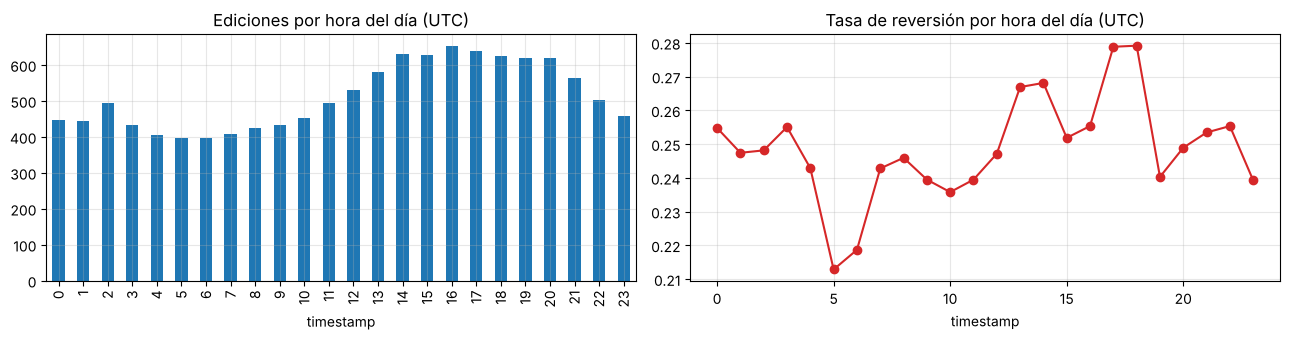

,ediciones,tasa_rev,media_cambio_tam,media_long_resumen
timestamp,,,,
2026-10-08,12022,0.270,1.38,2.42
2026-10-09,11790,0.254,1.35,2.40
2026-10-10,12277,0.249,1.43,2.47
2026-10-11,12470,0.236,1.47,2.45
2026-10-12,12772,0.249,1.36,2.39
2026-10-13,13070,0.258,1.28,2.40
2026-10-14,12332,0.266,1.38,2.49
2026-10-15,12822,0.257,1.37,2.42
2026-10-16,12175,0.252,1.41,2.42


In [5]:
# Perfil medio por hora del día: ¿hay un ciclo diario?
hora = df["timestamp"].dt.hour
perfil = pd.DataFrame({"ediciones (media por día)": y.groupby(hora).size() / df["timestamp"].dt.date.nunique(),
                       "tasa de reversión": y.groupby(hora).mean()})
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
perfil.iloc[:, 0].plot.bar(ax=ax[0], color="tab:blue"); ax[0].set_title("Ediciones por hora del día (UTC)")
perfil.iloc[:, 1].plot(ax=ax[1], marker="o", color="tab:red"); ax[1].set_title("Tasa de reversión por hora del día (UTC)")
plt.tight_layout(); plt.show()

# Resumen diario
dia = df["timestamp"].dt.date
pd.DataFrame({"ediciones": y.groupby(dia).size(), "tasa_rev": y.groupby(dia).mean().round(3),
              "media_cambio_tam": X["cambio_tam"].groupby(dia).mean().round(2),
              "media_long_resumen": X["long_resumen"].groupby(dia).mean().round(2)})

**Qué vemos en el flujo:**

- **Volumen estable entre días** (11.000–13.000 ediciones anónimas al día, unas 510 por hora de media) pero con un **ciclo diario muy marcado**: unas 400 ediciones/hora de madrugada (UTC) frente a más de 600 entre las 14 y las 20 UTC, cuando es de día en América.
- **La tasa de reversión también sigue un ciclo diario**: baja al 21 % hacia las 5 UTC y sube al 28 % hacia las 17–18 UTC (horario escolar en EE. UU., algo conocido en la comunidad de Wikipedia). Es decir, $P(y)$ y probablemente $P(y \mid X)$ cambian **de forma recurrente** cada día.
- **Las medias diarias de las variables apenas se mueven** (la de `cambio_tam` entre 1,28 y 1,47, la de `long_resumen` entre 2,39 y 2,49). Hora a hora sí hay mucho ruido: ráfagas de ediciones parecidas que mueven la media durante un rato.
- **El último día (17 de octubre) tiene menos reversiones (21 %)**. No creemos que sea un cambio real: descargamos los datos el 19, así que esas ediciones han tenido menos tiempo para ser revertidas. Es el problema de la **etiqueta retardada** y lo tenemos en cuenta al interpretar las alarmas de los últimos días.

**Conclusión del análisis exploratorio:** a simple vista no hay un cambio brusco y permanente en estos 10 días. Lo que domina es la **estacionalidad diaria** y el **ruido de ráfagas**. Esto es justo lo que los detectores tienen que saber distinguir de un drift real.

### 4.4 Estrategia de aprendizaje y evaluación

**Aprendizaje online.** Cada edición se procesa **una sola vez**: primero el modelo **predice** (test) y después **aprende** de ella (train). Es la evaluación *prequential* o *interleaved test-then-train* de la diapositiva S4, la misma que hace `evaluate.progressive_val_score`. Escribimos el bucle a mano (como en el notebook `HoeffdingDecisionTree_ModelDrift` del profesor) porque necesitamos, instancia a instancia, el **error del modelo** para alimentar los detectores de concept drift.

**Modelo.** Una **regresión logística online** de River sobre:
- las variables numéricas, estandarizadas de forma incremental (`StandardScaler`), y
- la bolsa de palabras del resumen (`BagOfWords`), que no necesita conocer el vocabulario de antemano.

Elegimos un modelo lineal porque es rápido, estable y fácil de interpretar; en esta fase el modelo es sobre todo el "sensor" cuyo error vigilaremos. Lo comparamos con un **Hoeffding Tree** (el árbol online visto en clase) para comprobar que la elección es razonable.

**Modelos de referencia (baseline).**
- `PriorClassifier`: predice siempre según la proporción de clases vista hasta el momento (no usa X). Es el mínimo a superar.
- `NoChangeClassifier`: predice la etiqueta de la edición anterior. Captura las ráfagas; si un modelo no lo supera, no está aprendiendo nada de las variables.

**Métricas.**
- **ROC AUC**: mide si el modelo **ordena** bien las ediciones por riesgo, que es justo el uso que queremos darle (priorizar la revisión). No depende del umbral.
- **Accuracy** (umbral 0,5): la métrica habitual, que además define el error 0/1 que necesitan los detectores binarios de concept drift. Veremos que con este desbalanceo el umbral 0,5 da problemas y lo ajustamos en 4.4.1.
- Además de las métricas acumuladas, mostramos su versión en **ventana deslizante** (prequential con ventana, S4), que refleja el estado actual del modelo y permite ver su evolución.

In [6]:
def nuevo_modelo_lr():
    numericas = compose.Select(*NUMERICAS) | preprocessing.StandardScaler()
    texto = feature_extraction.BagOfWords(on="resumen", lowercase=True)
    return (numericas + texto) | linear_model.LogisticRegression()

def prequential(modelo, X, y, nombre):
    # Bucle test-then-train. Devuelve probabilidades y errores (1 = fallo) de cada instancia.
    acc, auc = metrics.Accuracy(), metrics.ROCAUC()
    probas = np.empty(len(y)); errores = np.empty(len(y), dtype=int)
    t0 = time.time()
    for i, (x, yi) in enumerate(iter_frame(X, y)):
        p = modelo.predict_proba_one(x).get(True, 0.0)      # 1) test
        y_pred = p >= 0.5
        acc.update(yi, y_pred); auc.update(yi, p)
        probas[i], errores[i] = p, int(y_pred != yi)
        modelo.learn_one(x, yi)                              # 2) train
    print(f"{nombre:<28} Accuracy={acc.get():.3f}  ROC AUC={auc.get():.3f}  ({time.time() - t0:.0f}s)")
    return probas, errores

resultados = {}
resultados["Baseline: PriorClassifier"]   = prequential(dummy.PriorClassifier(), X, y, "Baseline: PriorClassifier")
resultados["Baseline: NoChange"]          = prequential(dummy.NoChangeClassifier(), X, y, "Baseline: NoChange")
resultados["Hoeffding Tree"]              = prequential(compose.Select(*NUMERICAS) | tree.HoeffdingTreeClassifier(), X, y, "Hoeffding Tree")
resultados["Regresión logística online"]  = prequential(nuevo_modelo_lr(), X, y, "Regresión logística online")

Baseline: PriorClassifier    Accuracy=0.750  ROC AUC=0.500  (2s)


Baseline: NoChange           Accuracy=0.627  ROC AUC=0.503  (3s)


Hoeffding Tree               Accuracy=0.753  ROC AUC=0.594  (12s)


Regresión logística online   Accuracy=0.756  ROC AUC=0.639  (10s)


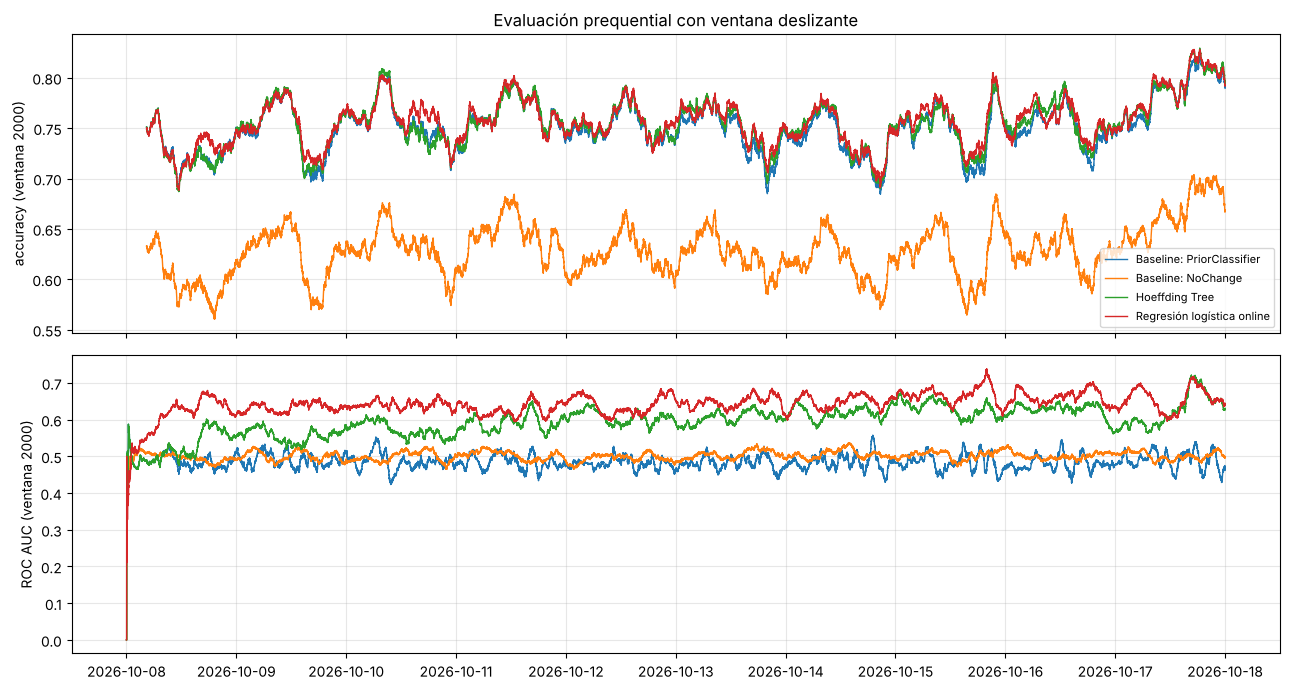

In [7]:
# Evolución de las métricas en ventana deslizante (últimas VENTANA ediciones)
VENTANA = 2000
yv = y.to_numpy()
fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for nombre, (p, e) in resultados.items():
    ax[0].plot(df["timestamp"], 1 - pd.Series(e).rolling(VENTANA).mean(), label=nombre, lw=1)
    rauc = metrics.RollingROCAUC(window_size=VENTANA)
    serie = []
    for yi, pi in zip(yv, p):
        rauc.update(yi, pi); serie.append(rauc.get())
    ax[1].plot(df["timestamp"], serie, label=nombre, lw=1)
ax[0].set_ylabel(f"accuracy (ventana {VENTANA})"); ax[1].set_ylabel(f"ROC AUC (ventana {VENTANA})")
ax[0].legend(loc="lower right", fontsize=8); ax[0].set_title("Evaluación prequential con ventana deslizante")
plt.tight_layout(); plt.show()

**Resultados de la evaluación prequential:**

| Modelo | Accuracy | ROC AUC |
|---|---|---|
| PriorClassifier (baseline) | 0,750 | 0,500 |
| NoChange (baseline) | 0,627 | 0,503 |
| Hoeffding Tree (solo numéricas) | 0,753 | 0,594 |
| **Regresión logística online (numéricas + texto)** | **0,756** | **0,639** |

- **La accuracy engaña**: el baseline que siempre dice "no revertida" ya acierta el 75 %, y los modelos apenas lo mejoran. Por eso usamos ROC AUC como métrica principal.
- **La regresión logística es el mejor modelo**: es la única que ordena las ediciones claramente mejor que el azar (AUC 0,64 frente a 0,50), y supera al Hoeffding Tree. Atribuimos la diferencia al **texto del resumen**, que el árbol no usa, y a que con pocas variables un modelo lineal converge antes que un árbol que tiene que esperar evidencia para dividir.
- **NoChange no aporta**: hay ráfagas, pero no bastan para predecir la siguiente edición.
- La AUC en ventana es **estable a lo largo de los 10 días** (en torno a 0,6–0,7, ver gráfica) y no hay una caída sostenida: un primer indicio de que no hay un concept drift fuerte en este periodo.
- **Eficiencia**: procesar las 122.679 ediciones cuesta unos 11 s (≈10.000 ediciones/s), varios órdenes de magnitud por encima del ritmo real del flujo (~500/hora).

El poder predictivo es modesto, lo que es esperable usando solo metadatos (sin el contenido del cambio ni el historial del usuario). Para el objetivo de esta parte, vigilar el drift, nos basta un modelo **estable** y claramente mejor que el azar. Mejorarlo es trabajo de la siguiente fase.

#### 4.4.1 Umbral de decisión: qué error vigilan los detectores

Los detectores de concept drift (DDM, EDDM, HDDM) reciben un 1 cuando el modelo **falla** y un 0 cuando acierta. Con el umbral por defecto (0,5) la regresión logística casi nunca predice "revertida" (ver celda siguiente), así que **fallar es prácticamente lo mismo que "la edición fue revertida"**: el flujo de errores sería casi una copia de la etiqueta y los detectores vigilarían la **tasa de reversión** $P(y)$, no si el modelo se equivoca más.

Por eso fijamos un umbral acorde al uso real del sistema: **marcar para revisión aproximadamente la misma proporción de ediciones que suele revertirse**. Para no usar información del futuro, el umbral se calcula **solo con el primer día del flujo** (el cuantil de las probabilidades que deja por encima la tasa de reversión de ese día) y se mantiene fijo después.

In [8]:
prob_lr, err_05 = resultados["Regresión logística online"]
yv = y.to_numpy()
fin_dia1 = int(np.searchsorted(df["timestamp"].to_numpy(), df["timestamp"].iloc[0].normalize() + pd.Timedelta(days=1)))
UMBRAL = float(np.quantile(prob_lr[:fin_dia1], 1 - yv[:fin_dia1].mean()))
err_lr = ((prob_lr >= UMBRAL) != yv).astype(int)

pd.DataFrame({
    "umbral": [0.5, round(UMBRAL, 3)],
    "% ediciones marcadas": [round(100 * (prob_lr >= 0.5).mean(), 1), round(100 * (prob_lr >= UMBRAL).mean(), 1)],
    "% de revertidas capturadas (recall)": [round(100 * (prob_lr[yv] >= 0.5).mean(), 1), round(100 * (prob_lr[yv] >= UMBRAL).mean(), 1)],
    "tasa de error": [round(err_05.mean(), 3), round(err_lr.mean(), 3)],
    "correlación error–etiqueta": [round(np.corrcoef(err_05, yv)[0, 1], 2), round(np.corrcoef(err_lr, yv)[0, 1], 2)],
}, index=["umbral 0,5", "umbral del día 1"])

,umbral,% ediciones marcadas,% de revertidas capturadas (recall),tasa de error,correlación error–etiqueta
"umbral 0,5",0.500,3.0,7.2,0.244,0.92
umbral del día 1,0.331,20.8,34.9,0.284,0.47


Con umbral 0,5 el modelo solo marca un 3 % de las ediciones y el error 0/1 tiene una **correlación de 0,92 con la etiqueta**. Los detectores de concept drift vigilarían en la práctica la tasa de reversión, no el comportamiento del modelo.

Con el umbral calculado el primer día (≈0,33) el sistema marca un 21 % de las ediciones para revisión y **captura el 35 % de las revertidas** (frente al 21 % que capturaría marcando al azar). La correlación error–etiqueta baja a 0,47: el flujo de errores ya refleja **aciertos y fallos del modelo**, que es lo que queremos vigilar. A partir de aquí todos los detectores de concept drift usan este flujo de errores.

### 4.5 Detección de data drift (cambios en $P(X)$)

Para el data drift **no hace falta la etiqueta**: basta con vigilar la distribución de las variables de entrada a medida que llegan. Es una ventaja importante en este problema, porque la etiqueta real llega con horas de retraso.

**Qué vigilamos.** Dos variables numéricas que, según el análisis anterior y la literatura, son de las más informativas: `cambio_tam` (cuánto texto se añade o quita) y `long_resumen` (cuánto escribe quien edita). Los detectores de River son univariantes, así que se monitoriza cada variable por separado.

**Técnicas elegidas y por qué:**

| Técnica | Qué detecta | Por qué la elegimos aquí |
|---|---|---|
| **KSWIN** | Cualquier cambio en la **distribución** (media, varianza, forma) entre una ventana reciente y una de referencia, con el test de Kolmogorov-Smirnov | Nuestras variables son muy asimétricas y con colas largas (bytes, longitud de texto): un cambio puede afectar a la forma sin mover mucho la media. KSWIN es el único de los tres que no se limita a la media |
| **ADWIN** | Cambios en la **media** con una ventana de tamaño **adaptativo** | No hay que fijar el tamaño de ventana a mano y tiene garantías estadísticas (δ). Sirve tanto para cambios bruscos como graduales |
| **Page-Hinkley** | Cambios **bruscos** en la media mediante una suma acumulada de desviaciones | Memoria constante y muy barato, pensado justo para flujos de alta velocidad. Lo incluimos como contraste: es sencillo pero sensible a su umbral |

Empezamos con los parámetros por defecto de River (los mismos que en los notebooks de clase) y en 4.7 analizamos cómo cambian los resultados al ajustarlos.

In [9]:
def detectar(detector_fabrica, serie):
    # Pasa una serie por un detector y devuelve los índices donde avisa de drift.
    det = detector_fabrica()
    alarmas = []
    for i, v in enumerate(serie):
        det.update(float(v))
        if det.drift_detected:
            alarmas.append(i)
    return alarmas

DETECTORES_DATA = {
    "KSWIN":        lambda: drift.KSWIN(alpha=0.005, window_size=100, stat_size=30, seed=SEMILLA),
    "ADWIN":        lambda: drift.ADWIN(delta=0.002),
    "Page-Hinkley": lambda: drift.PageHinkley(min_instances=30, delta=0.005, threshold=50),
}
VARS_DATA = ["cambio_tam", "long_resumen"]

alarmas_data = {(v, d): detectar(f, X[v].to_numpy()) for v in VARS_DATA for d, f in DETECTORES_DATA.items()}
pd.Series({f"{d} sobre {v}": len(a) for (v, d), a in alarmas_data.items()}, name="nº de alarmas").to_frame()

,nº de alarmas
KSWIN sobre cambio_tam,147
ADWIN sobre cambio_tam,10
Page-Hinkley sobre cambio_tam,1001
KSWIN sobre long_resumen,165
ADWIN sobre long_resumen,26
Page-Hinkley sobre long_resumen,272


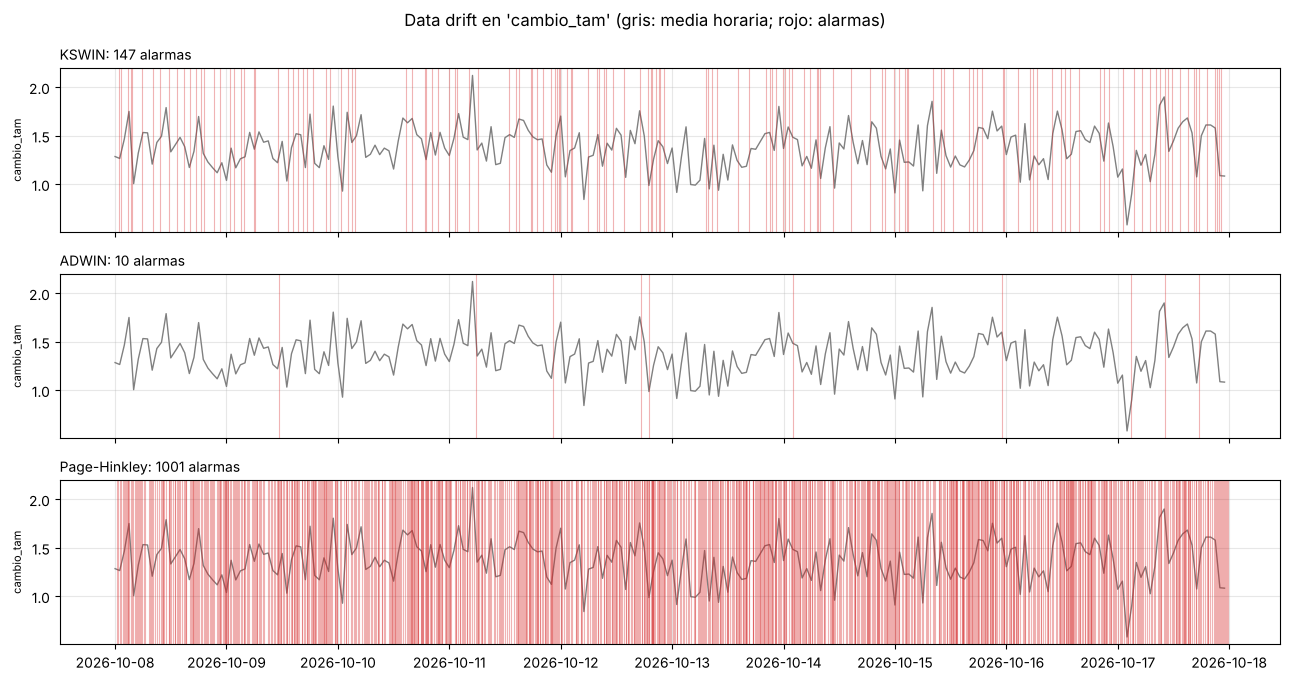

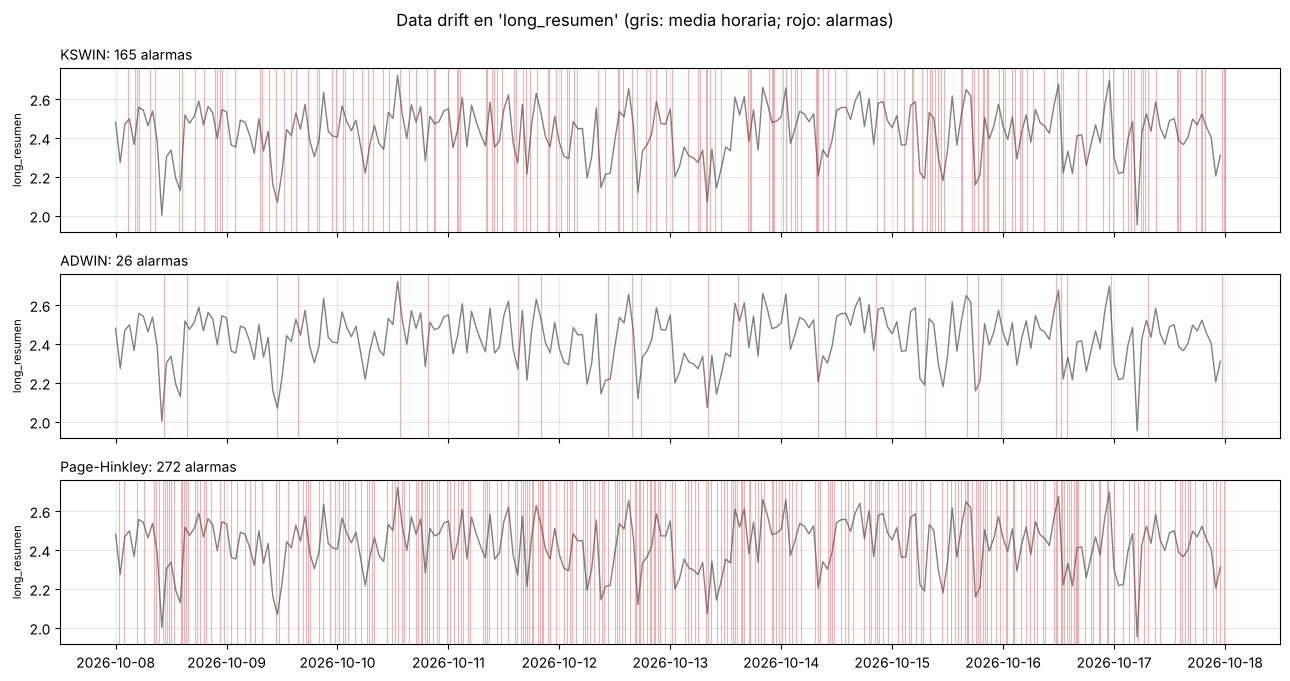

In [10]:
def dibujar_alarmas(serie_horaria, alarmas_dict, titulo, etiqueta_y):
    n = len(alarmas_dict)
    fig, ax = plt.subplots(n, 1, figsize=(13, 2.3 * n), sharex=True)
    for a, (nombre, idx) in zip(np.atleast_1d(ax), alarmas_dict.items()):
        a.plot(serie_horaria.index, serie_horaria.values, color="gray", lw=1)
        for i in idx:
            a.axvline(df["timestamp"].iloc[i], color="tab:red", alpha=0.35, lw=0.8)
        a.set_ylabel(etiqueta_y, fontsize=8)
        a.set_title(f"{nombre}: {len(idx)} alarmas", fontsize=10, loc="left")
    fig.suptitle(titulo); plt.tight_layout(); plt.show()

for v in VARS_DATA:
    dibujar_alarmas(por_hora[v], {d: alarmas_data[(v, d)] for d in DETECTORES_DATA},
                    f"Data drift en '{v}' (gris: media horaria; rojo: alarmas)", v)

**¿Son alarmas "reales"?** En un flujo real no sabemos dónde hay drift de verdad. Para valorar cada alarma comparamos la distribución de la variable en las `N` ediciones **anteriores** y **posteriores** a la alarma con el estadístico KS (tamaño del cambio, no el p-valor, que con miles de datos siempre sale significativo). Si el cambio es minúsculo, la alarma no tiene relevancia práctica. También miramos **a qué hora del día** saltan: si se concentran en las transiciones del ciclo diario, el detector está viendo la estacionalidad.

In [11]:
from scipy.stats import ks_2samp
N_CTX = 1000      # ediciones antes / después de cada alarma (~2 horas de flujo)
UMBRAL_KS = 0.10  # cambio que consideramos relevante en la práctica

def resumen_alarmas_data(v, idx):
    s = X[v].to_numpy()
    efectos = [ks_2samp(s[max(0, i - N_CTX):i], s[i:i + N_CTX]).statistic for i in idx if i >= 100 and i + 100 < len(s)]
    horas = df["timestamp"].iloc[idx].dt.hour
    return {"alarmas": len(idx),
            "alarmas por día": round(len(idx) / 10, 1),
            "KS mediano antes/después": round(float(np.median(efectos)), 3) if efectos else np.nan,
            "% alarmas con KS > 0,10": round(100 * np.mean(np.array(efectos) > UMBRAL_KS), 1) if efectos else np.nan,
            "hora más frecuente (UTC)": int(horas.mode().iloc[0]) if len(idx) else np.nan}

tabla_data = pd.DataFrame({f"{d} · {v}": resumen_alarmas_data(v, alarmas_data[(v, d)])
                           for v in VARS_DATA for d in DETECTORES_DATA}).T
tabla_data

,alarmas,alarmas por día,KS mediano antes/después,"% alarmas con KS > 0,10",hora más frecuente (UTC)
KSWIN · cambio_tam,147.0,14.7,0.046,2.7,21.0
ADWIN · cambio_tam,10.0,1.0,0.046,0.0,2.0
Page-Hinkley · cambio_tam,1001.0,100.1,0.046,2.4,18.0
KSWIN · long_resumen,165.0,16.5,0.055,7.3,7.0
ADWIN · long_resumen,26.0,2.6,0.054,3.8,15.0
Page-Hinkley · long_resumen,272.0,27.2,0.058,5.1,19.0


**Interpretación de las alarmas de data drift en el flujo real:**

- **Las alarmas no corresponden a cambios relevantes.** El tamaño mediano del cambio antes/después de cada alarma es pequeño (KS ≈ 0,05) en **los tres detectores**, y como mucho un 7 % de las alarmas supera un KS de 0,10. Coincide con el análisis exploratorio: en estos 10 días no hay un data drift fuerte ni permanente, solo fluctuaciones horarias.
- Por tanto, **cuantas menos alarmas, mejor** en el flujo real, y las diferencias entre detectores son enormes:
  - **ADWIN** da 1–2,6 alarmas/día, que caen en caídas puntuales de la media (se ven en la gráfica, por ejemplo el 8 de octubre hacia las 10:00 y el 17 de octubre).
  - **KSWIN** da unas 15 alarmas/día. Con una ventana de solo 100 datos, el test KS compara muestras de 30 frente a 70 ediciones, y con variables de colas largas y en ráfagas dos trozos tan pequeños difieren "significativamente" muy a menudo.
  - **Page-Hinkley** da 27–100 alarmas/día. Su umbral por defecto (50) está en las **unidades de la variable**: para `cambio_tam`, cuya desviación típica es 3,5, una suma acumulada de 50 se alcanza en pocas ediciones. Por eso PH es el que peor funciona con los parámetros por defecto.
- Ninguno de los tres sabe que el flujo tiene **ciclo diario**, así que una parte de las alarmas son el paso de un "régimen horario" a otro, un cambio recurrente y no permanente.

Sin un drift conocido no podemos decir qué detector **acierta**, solo cuál es más ruidoso. Por eso en 4.7 inyectamos un drift controlado.

### 4.6 Detección de concept drift (cambios en $P(y \mid X)$)

El concept drift no se ve mirando solo X: hay que mirar **si el modelo empieza a equivocarse más**. Por eso los detectores se alimentan con el **flujo de errores** de la regresión logística (1 = fallo, 0 = acierto, con el umbral de 4.4.1), calculado en el bucle prequential *antes* de que el modelo aprenda de cada instancia, igual que en el notebook `HoeffdingDecisionTree_ModelDrift`.

**Técnicas elegidas y por qué:**

| Técnica | Idea | Por qué la elegimos aquí |
|---|---|---|
| **DDM** | Vigila la tasa de error $p_i$ y su desviación $s_i$; avisa si $p_i + s_i$ supera el mínimo histórico en 2σ (warning) o 3σ (drift) | Es el detector de referencia, simple y rápido ante **cambios bruscos** (p. ej. una oleada de vandalismo o un cambio en la política de reversión) |
| **EDDM** | Vigila la **distancia entre errores consecutivos**: si los errores se acercan, algo cambia | Diseñado para **cambios graduales**, que esperamos en Wikipedia (el comportamiento de editores y revisores cambia poco a poco) |
| **HDDM_W** | Compara la media de errores reciente (media móvil exponencial) con la histórica usando la **desigualdad de Hoeffding** | Tiene garantías estadísticas y, al ponderar lo reciente, reacciona tanto a cambios bruscos como graduales. Es el más robusto de los tres según la teoría |

Los tres son detectores **binarios** (entrada 0/1), que es exactamente lo que produce el bucle prequential. Usamos los parámetros por defecto de River. Igual que hacen DDM y HDDM en River, tras cada alarma el detector se reinicia y sigue vigilando; en esta fase **no** adaptamos el modelo (eso será la siguiente parte), solo detectamos.

In [12]:
def detectar_binario(fabrica, errores):
    det = fabrica()
    alarmas, avisos, en_warning = [], [], False
    for i, e in enumerate(errores):
        det.update(int(e))
        if det.drift_detected:
            alarmas.append(i); en_warning = False
        elif getattr(det, "warning_detected", False) and not en_warning:
            avisos.append(i); en_warning = True
    return alarmas, avisos

DETECTORES_CONCEPTO = {
    "DDM":    lambda: drift.binary.DDM(warm_start=30, warning_threshold=2.0, drift_threshold=3.0),
    "EDDM":   lambda: drift.binary.EDDM(warm_start=30, alpha=0.95, beta=0.9),
    "HDDM_W": lambda: HDDM_W(drift_confidence=0.001, warning_confidence=0.005, lambda_val=0.05),
}

alarmas_concepto = {}   # err_lr: errores con el umbral del día 1 (sección 4.4.1)
for nombre, fab in DETECTORES_CONCEPTO.items():
    alarmas_concepto[nombre], avisos = detectar_binario(fab, err_lr)
    print(f"{nombre:<7} {len(alarmas_concepto[nombre]):>4} alarmas de drift, {len(avisos):>4} zonas de warning")

DDM       18 alarmas de drift,   19 zonas de warning
EDDM     160 alarmas de drift,   80 zonas de warning


HDDM_W    89 alarmas de drift,   90 zonas de warning


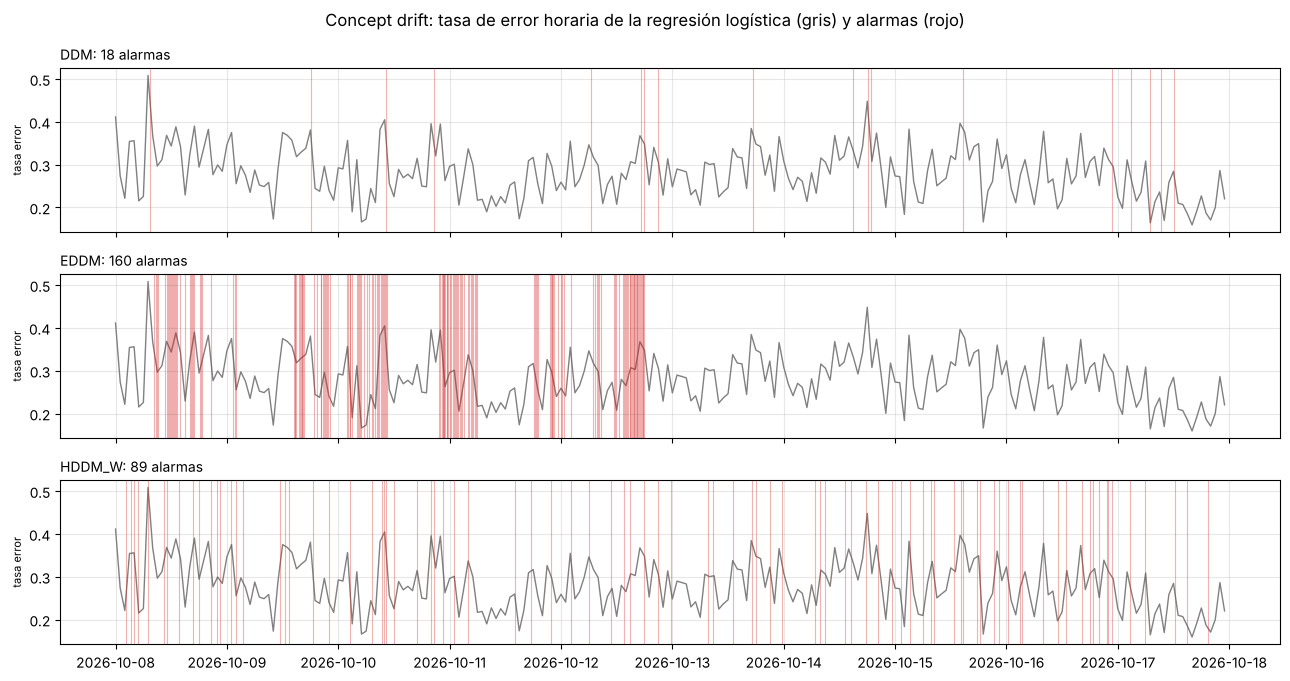

In [13]:
err_horario = pd.Series(err_lr).groupby(df["timestamp"].dt.floor("h").to_numpy()).mean()
dibujar_alarmas(err_horario, alarmas_concepto,
                "Concept drift: tasa de error horaria de la regresión logística (gris) y alarmas (rojo)", "tasa error")

In [14]:
# ¿Tras cada alarma el modelo realmente falla más? Comparamos la tasa de error antes y después.
def resumen_alarmas_concepto(idx, errores, n=N_CTX):
    filas = []
    for i in idx:
        if i < n or i + n > len(errores):
            continue
        antes, despues = errores[i - n:i].mean(), errores[i:i + n].mean()
        filas.append(despues - antes)
    filas = np.array(filas)
    horas = df["timestamp"].iloc[idx].dt.hour
    return {"alarmas": len(idx),
            "Δ error medio (después − antes)": round(float(filas.mean()), 3) if len(filas) else np.nan,
            "% alarmas en las que el error sube": round(100 * np.mean(filas > 0), 1) if len(filas) else np.nan,
            "hora más frecuente (UTC)": int(horas.mode().iloc[0]) if len(idx) else np.nan}

pd.DataFrame({d: resumen_alarmas_concepto(a, err_lr) for d, a in alarmas_concepto.items()}).T

,alarmas,Δ error medio (después − antes),% alarmas en las que el error sube,hora más frecuente (UTC)
DDM,18.0,0.000,44.4,17.0
EDDM,160.0,-0.006,43.1,16.0
HDDM_W,89.0,0.019,61.8,17.0


**Interpretación de las alarmas de concept drift en el flujo real:**

- **No hay evidencia de un concept drift persistente.** El error medio del modelo no sube de forma sostenida tras las alarmas (Δ = 0,000 para DDM, −0,006 para EDDM y +0,019 para HDDM_W) y solo en torno a la mitad de las alarmas va seguida de un error mayor. Encaja con que la AUC en ventana sea estable (4.4).
- La gráfica muestra que la tasa de error tiene el **mismo ciclo diario** que la tasa de reversión (entre 0,2 y 0,4). Gran parte de las alarmas son esas subidas diarias: un cambio **recurrente** (el concepto de "vandalismo" a las 17 UTC no es igual que a las 5 UTC) que se repite cada día.
- Comportamiento de cada detector:
  - **DDM** (18 alarmas, <2/día) es el más conservador. Compara con el **mínimo histórico** de una tasa de error acumulada, que con decenas de miles de ediciones cambia muy despacio. Ignora las oscilaciones diarias.
  - **HDDM_W** (89 alarmas, ~9/día) es el más reactivo. Su media móvil exponencial pesa mucho lo reciente, así que "ve" cada subida diaria. Sus alarmas son las únicas con subida media del error positiva (+0,019): reacciona a subidas reales, aunque sean transitorias.
  - **EDDM** (160 alarmas) es el más errático. Se concentran en los primeros días y luego desaparecen. EDDM vigila la **distancia entre errores consecutivos**, pensada para modelos con pocos errores. Aquí el modelo falla en un 28 % de las ediciones (un error cada ~3,5 ediciones de media), así que las distancias son minúsculas, las ráfagas las alteran mucho y el máximo histórico que usa de referencia se va desplazando.

### 4.7 Validación controlada: drift inyectado en el propio flujo

En el flujo real no hay una "verdad" sobre dónde ocurre el drift, así que no podemos medir directamente qué detector es mejor. Para poder **compararlos con números** tratamos el flujo como **semi-sintético**: tomamos los mismos 10 días e **introducimos un cambio conocido** a partir del día 6 (instancia $t_0$, 13 de octubre a las 00:00 UTC). Antes de $t_0$ el flujo es el real, así que podemos medir:

- **Falsas alarmas**: alarmas por día antes de $t_0$.
- **Retardo de detección**: ediciones (y minutos) desde $t_0$ hasta la primera alarma.

Diseñamos dos escenarios **puros**, para comprobar además que cada familia de detectores responde solo al tipo de drift que le corresponde:

1. **Data drift puro.** Wikipedia cambia su editor para que el resumen incluya un texto automático (por ejemplo, una etiqueta de la app móvil): cada resumen gana unos 25 caracteres. Cambia $P(X)$, pero **las etiquetas no cambian**.
2. **Concept drift puro.** Tras un ataque coordinado, los patrulleros pasan a ser mucho más estrictos y revierten también un 15 % de las ediciones que antes habrían aceptado, **sin que eso dependa de X**. Las variables no cambian; cambia $P(y \mid X)$.

> En una primera versión el concept drift inyectado era "a partir de $t_0$ se revierte lo que quita texto". Ningún detector lo vio, y no por fallo suyo: esa regla depende de una variable que el modelo ya tiene (`quita_texto`), así que la regresión logística **se adaptó sola** en pocas instancias y su error incluso bajó. Es una lección útil: el aprendizaje online absorbe por sí mismo los cambios de concepto que puede representar. Para comparar detectores hace falta un cambio que el modelo no pueda absorber, como el del escenario 2.

In [15]:
t0 = int(np.searchsorted(df["timestamp"].to_numpy(), np.datetime64("2026-10-13T00:00:00")))
print(f"Drift inyectado a partir de la instancia t0 = {t0:,} ({df['timestamp'].iloc[t0]})")

# Escenario 1: data drift puro -> el resumen pasa a llevar un texto automático de ~25 caracteres
X_data = X.copy()
long_orig = np.expm1(X["long_resumen"])
X_data.loc[t0:, "long_resumen"] = np.log1p(long_orig[t0:] + 25)

# Escenario 2: concept drift puro -> desde t0 se revierte además un 15 % de las ediciones que se habrían aceptado
rng = np.random.default_rng(SEMILLA)
y_conc = y.copy()
nuevas_rev = (rng.random(len(y)) < 0.15) & ~yv
nuevas_rev[:t0] = False
y_conc[nuevas_rev] = True
print(f"Tasa de reversión antes de t0: {y[:t0].mean():.1%} | después en el escenario 2: {y_conc[t0:].mean():.1%}")

Drift inyectado a partir de la instancia t0 = 61,331 (2026-10-13 00:00:03)
Tasa de reversión antes de t0: 25.1% | después en el escenario 2: 36.1%


In [16]:
def evaluar_inyeccion(alarmas, t0):
    antes = [a for a in alarmas if a < t0]
    despues = [a for a in alarmas if a >= t0]
    dias_antes = (df["timestamp"].iloc[t0] - df["timestamp"].iloc[0]).total_seconds() / 86400
    dias_despues = (df["timestamp"].iloc[-1] - df["timestamp"].iloc[t0]).total_seconds() / 86400
    return {"alarmas/día antes de t0 (falsas)": round(len(antes) / dias_antes, 1),
            "alarmas/día después de t0": round(len(despues) / dias_despues, 1),
            "retardo 1ª alarma (ediciones)": (despues[0] - t0) if despues else np.nan,
            "retardo 1ª alarma (minutos)": round((df["timestamp"].iloc[despues[0]] - df["timestamp"].iloc[t0]).total_seconds() / 60, 1) if despues else np.nan}

def errores(prob, etiquetas):
    return ((prob >= UMBRAL) != np.asarray(etiquetas)).astype(int)

# Escenario 1 (data drift): detectores de data drift sobre long_resumen...
filas = {f"{d} (data)": evaluar_inyeccion(detectar(f, X_data["long_resumen"].to_numpy()), t0) for d, f in DETECTORES_DATA.items()}
# ...y detectores de concept drift sobre el error del modelo, que NO deberían reaccionar (y no cambia)
prob_esc1, _ = prequential(nuevo_modelo_lr(), X_data, y, "LR en escenario 1")
err_esc1 = errores(prob_esc1, y)
filas.update({f"{d} (concepto)": evaluar_inyeccion(detectar_binario(f, err_esc1)[0], t0) for d, f in DETECTORES_CONCEPTO.items()})
print("Escenario 1 · data drift puro")
pd.DataFrame(filas).T

LR en escenario 1            Accuracy=0.755  ROC AUC=0.634  (11s)


Escenario 1 · data drift puro


,alarmas/día antes de t0 (falsas),alarmas/día después de t0,retardo 1ª alarma (ediciones),retardo 1ª alarma (minutos)
KSWIN (data),15.2,18.2,19.0,1.8
ADWIN (data),2.2,2.2,44.0,5.0
Page-Hinkley (data),27.0,4.8,38.0,3.2
DDM (concepto),1.6,0.6,8075.0,952.0
EDDM (concepto),32.0,0.0,NaN,NaN
HDDM_W (concepto),8.8,10.6,1570.0,218.3


In [17]:
# Escenario 2 (concept drift): re-ejecutamos el prequential con las nuevas etiquetas
prob_esc2, _ = prequential(nuevo_modelo_lr(), X, y_conc, "LR en escenario 2")
err_esc2 = errores(prob_esc2, y_conc)
print(f"Tasa de error del modelo: 5000 ediciones antes de t0 = {err_esc2[t0-5000:t0].mean():.3f} | "
      f"5000 después = {err_esc2[t0:t0+5000].mean():.3f}")
filas = {f"{d} (concepto)": evaluar_inyeccion(detectar_binario(f, err_esc2)[0], t0) for d, f in DETECTORES_CONCEPTO.items()}
print("Escenario 2 · concept drift puro  (X no cambia: los detectores de data drift se comportan igual que en 4.5)")
pd.DataFrame(filas).T

LR en escenario 2            Accuracy=0.704  ROC AUC=0.633  (10s)
Tasa de error del modelo: 5000 ediciones antes de t0 = 0.310 | 5000 después = 0.429


Escenario 2 · concept drift puro  (X no cambia: los detectores de data drift se comportan igual que en 4.5)


,alarmas/día antes de t0 (falsas),alarmas/día después de t0,retardo 1ª alarma (ediciones),retardo 1ª alarma (minutos)
DDM (concepto),1.6,0.8,179.0,27.8
EDDM (concepto),32.0,1.0,1073.0,150.8
HDDM_W (concepto),8.8,14.4,179.0,27.8


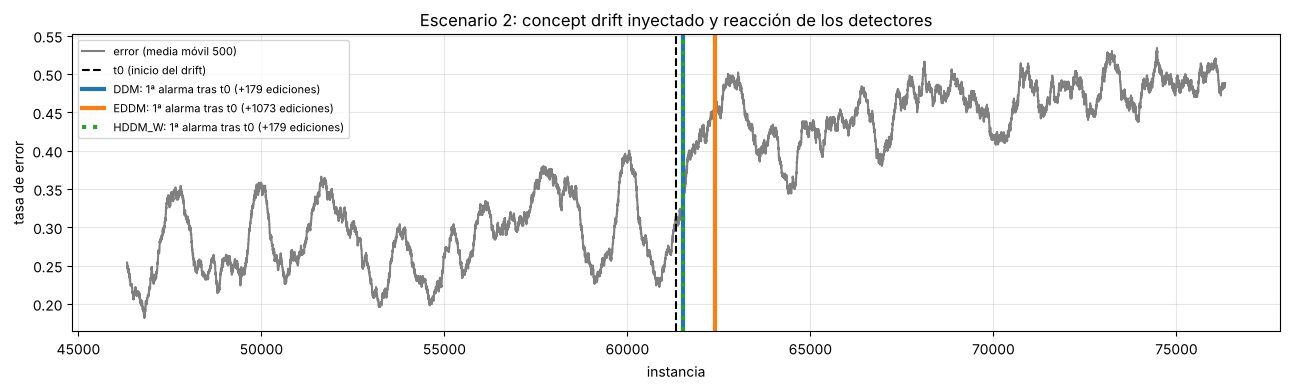

In [18]:
# Error del modelo alrededor de t0 en el escenario 2 y primera alarma de cada detector tras t0
ventana = slice(t0 - 15000, t0 + 15000)
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(np.arange(len(err_esc2))[ventana], pd.Series(err_esc2).rolling(500).mean().iloc[ventana], color="gray", label="error (media móvil 500)")
ax.axvline(t0, color="k", ls="--", label="t0 (inicio del drift)")
for (d, f), c, ls in zip(DETECTORES_CONCEPTO.items(), ["tab:blue", "tab:orange", "tab:green"], ["-", "-", ":"]):
    tras = [a for a in detectar_binario(f, err_esc2)[0] if a >= t0]
    if tras:
        ax.axvline(tras[0], color=c, lw=3, ls=ls, label=f"{d}: 1ª alarma tras t0 (+{tras[0] - t0} ediciones)")
ax.set_xlabel("instancia"); ax.set_ylabel("tasa de error"); ax.legend(fontsize=8)
ax.set_title("Escenario 2: concept drift inyectado y reacción de los detectores")
plt.tight_layout(); plt.show()

**Sensibilidad a los parámetros.** Hasta aquí hemos usado los parámetros por defecto de River. Como algunos detectores dan muchas falsas alarmas, comprobamos si se debe a la técnica o a sus parámetros, probando un ajuste razonable de cada uno. Así la comparación final es justa.

In [19]:
AJUSTES_DATA = {
    "KSWIN (por defecto: ventana 100/30, α=0,005)": DETECTORES_DATA["KSWIN"],
    "KSWIN (ventana 1000/300, α=1e-4)": lambda: drift.KSWIN(alpha=1e-4, window_size=1000, stat_size=300, seed=SEMILLA),
    "ADWIN (por defecto: δ=0,002)": DETECTORES_DATA["ADWIN"],
    "ADWIN (δ=1e-4)": lambda: drift.ADWIN(delta=1e-4),
    "Page-Hinkley (por defecto: umbral 50)": DETECTORES_DATA["Page-Hinkley"],
    "Page-Hinkley (umbral 200)": lambda: drift.PageHinkley(min_instances=30, delta=0.005, threshold=200),
}
AJUSTES_CONCEPTO = {
    "DDM (por defecto: 3σ)": DETECTORES_CONCEPTO["DDM"],
    "EDDM (por defecto: β=0,9)": DETECTORES_CONCEPTO["EDDM"],
    "HDDM_W (por defecto: confianza 0,001)": DETECTORES_CONCEPTO["HDDM_W"],
    "HDDM_W (confianza 1e-5)": lambda: HDDM_W(drift_confidence=1e-5, warning_confidence=1e-4, lambda_val=0.05),
}
sens = {k: evaluar_inyeccion(detectar(f, X_data["long_resumen"].to_numpy()), t0) for k, f in AJUSTES_DATA.items()}
sens.update({k: evaluar_inyeccion(detectar_binario(f, err_esc2)[0], t0) for k, f in AJUSTES_CONCEPTO.items()})
pd.DataFrame(sens).T.drop(columns="alarmas/día después de t0")

,alarmas/día antes de t0 (falsas),retardo 1ª alarma (ediciones),retardo 1ª alarma (minutos)
"KSWIN (por defecto: ventana 100/30, α=0,005)",15.2,19.0,1.8
"KSWIN (ventana 1000/300, α=1e-4)",3.8,64.0,8.1
"ADWIN (por defecto: δ=0,002)",2.2,44.0,5.0
ADWIN (δ=1e-4),1.4,76.0,9.9
Page-Hinkley (por defecto: umbral 50),27.0,38.0,3.2
Page-Hinkley (umbral 200),3.4,76.0,9.9
DDM (por defecto: 3σ),1.6,179.0,27.8
"EDDM (por defecto: β=0,9)",32.0,1073.0,150.8
"HDDM_W (por defecto: confianza 0,001)",8.8,179.0,27.8
HDDM_W (confianza 1e-5),2.4,179.0,27.8


**Resultados de la validación controlada:**

*Escenario 1 (data drift puro, +25 caracteres en el resumen):*
- **Los tres detectores de data drift lo detectan casi de inmediato** (KSWIN en 19 ediciones ≈ 2 min, Page-Hinkley en 38 ≈ 3 min, ADWIN en 44 ≈ 5 min). Es un cambio de magnitud clara.
- La diferencia está en el **coste en falsas alarmas**: antes de $t_0$, ADWIN da 2,2 alarmas/día, KSWIN 15 y Page-Hinkley 27. Ganar 3 minutos de retardo no compensa multiplicar por 7–12 las falsas alarmas.
- **Los detectores de concept drift no reaccionan**, como debe ser: DDM y EDDM no aumentan sus alarmas tras $t_0$ y HDDM_W pasa de 8,8 a 10,6/día, dentro de su ruido habitual. Hay **data drift sin concept drift**: el texto añadido no cambia qué ediciones se revierten, y el modelo (que estandariza de forma incremental) absorbe el cambio sin perder rendimiento (AUC 0,634 frente a 0,639).

*Escenario 2 (concept drift puro, +15 % de reversiones independientes de X):*
- El error del modelo salta de **0,31 a 0,43** y se queda alto, porque el cambio no depende de ninguna variable y el modelo no puede aprenderlo.
- **DDM y HDDM_W lo detectan a las 179 ediciones (~28 min)** y **EDDM tarda 1.073 (~2,5 h)**: EDDM está pensado para cambios graduales y es lento ante un cambio brusco.
- Con el mismo retardo, **DDM tiene muchas menos falsas alarmas que HDDM_W** (1,6 frente a 8,8/día). EDDM es el peor en ambas cosas (32 falsas alarmas/día).
- Los detectores de data drift no pueden verlo: X no cambia. Es la razón de vigilar ambas cosas por separado.

*Sensibilidad a los parámetros:*
- **Los parámetros explican buena parte de las falsas alarmas.** Agrandar la ventana de KSWIN (1000/300) baja sus falsas alarmas de 15 a 3,8/día, y subir el umbral de Page-Hinkley a 200 las baja de 27 a 3,4/día, a cambio de un retardo de unos 8–10 minutos en vez de 2–3.
- **ADWIN ya da ese equilibrio sin ajustar nada** (2,2/día y 5 min), y con δ más estricto baja a 1,4/día. Es la ventaja de su ventana adaptativa: no hay que adivinar el tamaño de ventana adecuado para el flujo.
- **HDDM_W con confianza 1e-5 iguala a DDM en falsas alarmas (2,4/día) sin perder rapidez** (179 ediciones).

### 4.8 Comparativa y justificación

| | Técnica | ¿Por qué la elegimos? | ¿Qué ha pasado? | Veredicto |
|---|---|---|---|---|
| **Data drift** | **ADWIN** | Ventana adaptativa, garantías estadísticas, sin fijar tamaño de ventana | Detecta en 5 min con solo ~2 falsas alarmas/día, **sin ajustar parámetros** | ✅ **Elegido**. Mejor equilibrio retardo/ruido |
| | KSWIN | Detecta cambios en toda la distribución, no solo la media (variables asimétricas) | El más rápido (2 min), pero con ventana 100 da 15 falsas alarmas/día: el test KS sobre muestras tan pequeñas es demasiado sensible a ráfagas. Con ventana 1000 mejora mucho | ⚠️ Útil con una ventana mayor; complementario para cambios de forma |
| | Page-Hinkley | Muy barato, pensado para cambios bruscos | Umbral en unidades de la variable: con el valor por defecto da 27–100 alarmas/día. Con umbral 200 es aceptable | ❌ Exige calibrar el umbral por variable |
| **Concept drift** | **DDM** | Referencia clásica, rápido ante cambios bruscos | Detecta el drift inyectado en ~28 min con las menores falsas alarmas (1,6/día) e ignora el ciclo diario | ✅ **Elegido** (junto con HDDM_W ajustado) |
| | **HDDM_W** | Garantías de Hoeffding y media ponderada: cambios bruscos y graduales | Igual de rápido que DDM; con parámetros por defecto reacciona al ciclo diario (~9 alarmas/día). Con confianza 1e-5 iguala a DDM en ruido | ✅ Con confianza 1e-5. Además da zonas de *warning* útiles para la adaptación |
| | EDDM | Diseñado para cambios graduales | El más lento (2,5 h) y el más ruidoso (32/día): con un 28 % de error las distancias entre errores no son informativas | ❌ No adecuado para un modelo con tasa de error alta |

**Por qué unos funcionan mejor que otros, en resumen:**
1. **Las características del flujo deciden**: colas largas, ráfagas y ciclo diario penalizan a los detectores con ventanas fijas pequeñas (KSWIN) o umbrales absolutos (PH), y favorecen a los que adaptan su referencia (ADWIN) o la estiman sobre mucha historia (DDM).
2. **La tasa de error base del modelo importa**: EDDM asume errores poco frecuentes, y aquí no lo son.
3. **El modelo online absorbe parte del drift por sí solo**: un cambio de concepto que el modelo puede representar con sus variables no llega a subir el error (nuestra primera versión del escenario 2). Lo que hay que vigilar son los cambios que el modelo **no** puede seguir.
4. **El umbral de decisión condiciona qué detecta un detector "de concept drift"**: con umbral 0,5 habríamos vigilado la tasa de reversión y no los errores del modelo.

## 5. Conclusiones (provisionales) y siguientes pasos

- Hemos planteado la priorización de ediciones de Wikipedia como un problema de **aprendizaje en flujo**: 122.679 ediciones anónimas reales de 10 días, reproducidas en orden con River y evaluadas de forma **prequential**. La **regresión logística online** con texto del resumen es el mejor modelo (ROC AUC 0,64 frente a 0,50 de los baselines) y procesa ~10.000 ediciones/s.
- En el **flujo real** de estos 10 días **no hay un data drift ni un concept drift fuertes y permanentes**. Lo que domina es un **cambio recurrente diario** (volumen, tasa de reversión y error del modelo suben por la tarde UTC) más ruido de ráfagas. La AUC del modelo se mantiene estable.
- Con el **drift inyectado** hemos podido comparar los detectores con números: **ADWIN** para data drift y **DDM / HDDM_W (confianza 1e-5)** para concept drift detectan en minutos con pocas falsas alarmas. **EDDM**, y Page-Hinkley y KSWIN con sus parámetros por defecto, no se ajustan a las características de este flujo.

**Limitaciones:**
- **Etiqueta retardada**: hemos dado la etiqueta justo después de predecir. En la realidad llega horas después (lo vemos en la menor tasa de reversión del último día), lo que retrasaría la detección de concept drift. River permite simularlo con `delay` en `progressive_val_score`.
- **10 días** permiten ver ciclos diarios pero no semanales ni cambios lentos de más largo plazo.
- Los drifts inyectados son **simplificaciones** (abruptos y puros); un drift real puede ser gradual o mezclar ambos tipos.
- Usamos **solo metadatos y el resumen**; el contenido del cambio o el historial del usuario mejorarían el modelo.

**Siguientes pasos (segunda parte del proyecto):**
1. **Adaptación al drift**: reaccionar a las alarmas de DDM / HDDM_W (reinicio del modelo, ventana deslizante o ponderación temporal) y comparar con modelos que se adaptan solos, como el *Hoeffding Adaptive Tree* o el *Adaptive Random Forest* (ARF), que usa ADWIN internamente.
2. Tratar el **ciclo diario** como cambio recurrente (por ejemplo, incluir la hora como contexto o usar modelos especializados), en lugar de reentrenar en cada alarma.
3. Evaluar con **etiqueta retardada** (`delay`) para acercarnos al funcionamiento real.

## Referencias

- Adler, B. T., de Alfaro, L., Mola-Velasco, S. M., Rosso, P., West, A. G. (2011). *Wikipedia vandalism detection: combining natural language, metadata, and reputation features*. CICLing.
- Baena-García, M., del Campo-Ávila, J., Fidalgo, R., Bifet, A., Gavaldà, R., Morales-Bueno, R. (2006). *Early drift detection method*. IWKDDS.
- Bifet, A., Gavaldà, R. (2007). *Learning from time-changing data with adaptive windowing*. SIAM SDM.
- Dawid, A. P. (1984). *Present position and potential developments: some personal views. Statistical theory: the prequential approach*. JRSS A.
- Frías-Blanco, I., del Campo-Ávila, J., Ramos-Jiménez, G., Morales-Bueno, R., Ortiz-Díaz, A., Caballero-Mota, Y. (2015). *Online and non-parametric drift detection methods based on Hoeffding's bounds*. IEEE TKDE.
- Gama, J., Medas, P., Castillo, G., Rodrigues, P. (2004). *Learning with drift detection*. SBIA.
- Gama, J., Žliobaitė, I., Bifet, A., Pechenizkiy, M., Bouchachia, A. (2014). *A survey on concept drift adaptation*. ACM Computing Surveys.
- Montiel, J. et al. (2021). *River: machine learning for streaming data in Python*. JMLR.
- Page, E. S. (1954). *Continuous inspection schemes*. Biometrika.
- Potthast, M., Stein, B., Gerling, R. (2008). *Automatic vandalism detection in Wikipedia*. ECIR.
- Raab, C., Heusinger, M., Schleif, F.-M. (2020). *Reactive soft prototype computing for concept drift streams*. Neurocomputing (KSWIN).
- Diapositivas y notebooks de la asignatura (S1–S5).